# 10 · Keeping the decline cap: a label-free λ controller

**Problem** ([`reports/backtest.md`](../reports/backtest.md)): in the replay, the share of good customers declined drifted up to 1.9% in some weeks although the cap is 1%. Each model's penalty λ was set on half of two labelled weeks, which is noisy: λ ranged from $36 to $76 across models.

**Fix.** At the end of each week, the model that will be in force next week scores **last week's whole traffic**. λ is then chosen so that the *expected* share of good customers declined, Σ(1−p) over declines divided by Σ(1−p) over everything, equals the target.
- It uses about 20k transactions instead of about 10k labelled ones.
- It needs **no labels**: declined transactions never get labels in production anyway.
- It follows the traffic as it changes.

It relies on the probabilities being calibrated, which is checked here.

This notebook re-runs the P4 replay from the cached model snapshots of notebook 09; no model is retrained.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fraud.backtest import POLICIES, controller_penalties, retrain_schedule, simulate
from fraud.config import load_config
from fraud.data import ENTITY_COL, PROCESSED_DIR, TARGET, load_dataset
from fraud.decision import load_costs, paired_cost_diff
from fraud.drift import apply_alarm_rules

mcfg = load_config("monitoring")
rcfg = mcfg["retraining"]
costs = load_costs()
CAP = costs["constraints"]["max_good_decline_rate"]
LAUNCH, PERIOD = rcfg["launch_week"], rcfg["period_weeks"]
WEEKS = list(range(LAUNCH, 27))
FIG_DIR, SNAP_DIR = Path("../reports/figures"), PROCESSED_DIR / "backtest_snapshots"

df = load_dataset("train")
evaluation = df.loc[df["week"] >= LAUNCH, ["TransactionID", "week", "day", "TransactionAmt", TARGET, ENTITY_COL]].reset_index(drop=True)
ends = sorted(int(p.stem.split("_")[1]) for p in SNAP_DIR.glob("end_*.parquet"))
snapshots = {e: pd.read_parquet(SNAP_DIR / f"end_{e}.parquet") for e in ends}
meta = pd.DataFrame([json.loads((SNAP_DIR / f"end_{e}.json").read_text()) for e in ends]).set_index("end")
thresholds = {k: v for k, v in mcfg["alarm_rules"].items() if k != "trend_rho"}
alarm_weeks = [w for w in apply_alarm_rules(pd.read_parquet(PROCESSED_DIR / "tuning_monitor_replay.parquet"), thresholds).query("any").index if w >= LAUNCH]
print(f"{len(snapshots)} cached models; live weeks {WEEKS[0]}-{WEEKS[-1]}; cap {CAP:.1%}")

13 cached models; live weeks 12-26; cap 1.0%


In [2]:
METHODS = {"calibration half (before)": None, "controller, target 1.0%": 0.010, "controller, target 0.9%": 0.009}
rows, weekly, cost_by = [], {}, {}
for delay in [2, 4]:
    for policy in POLICIES:
        schedule = retrain_schedule(policy, WEEKS, LAUNCH, delay, alarm_weeks, PERIOD)
        for method, target in METHODS.items():
            penalties = None if target is None else controller_penalties(evaluation, snapshots, schedule, costs, target)
            w, c = simulate(evaluation, snapshots, meta, schedule, costs, "bayes", penalties)
            weekly[delay, policy, method], cost_by[delay, policy, method] = w, c
            g = w["good_customers_declined"]
            rows.append({"delay": delay, "policy": policy, "method": method,
                         "weeks_over_cap": int((g > CAP).sum()), "mean_rate": g.mean(), "max_rate": g.max(),
                         "total_cost": c.sum(), "fraud_usd_stopped": w["fraud_usd_stopped"].mean()})
summary = pd.DataFrame(rows).set_index(["delay", "policy", "method"])
summary.round(4)

weeks_over_cap  mean_rate  max_rate  \
delay policy   method                                                           
2     never    calibration half (before)               5     0.0094    0.0118   
               controller, target 1.0%                 9     0.0099    0.0142   
               controller, target 0.9%                 3     0.0091    0.0131   
      periodic calibration half (before)               7     0.0102    0.0140   
               controller, target 1.0%                 9     0.0106    0.0156   
               controller, target 0.9%                 6     0.0097    0.0146   
      drift    calibration half (before)               5     0.0100    0.0137   
               controller, target 1.0%                 9     0.0106    0.0146   
               controller, target 0.9%                 8     0.0098    0.0133   
      weekly   calibration half (before)               9     0.0109    0.0142   
               controller, target 1.0%                 9     0.0107    0.0156   
               controller, target 0.9%                 8     0.0099    0.0146   
4     never    calibration half (before)               5     0.0094    0.0118   
               controller, target 1.0%                 9     0.0099    0.0142   
               controller, target 0.9%                 3     0.0091    0.0131   
      periodic calibration half (before)               8     0.0114    0.0194   
               controller, target 1.0%                 9     0.0107    0.0150   
               controller, target 0.9%                 8     0.0099    0.0142   
      drift    calibration half (before)               8     0.0114    0.0188   
               controller, target 1.0%                 9     0.0108    0.0150   
               controller, target 0.9%                 8     0.0100    0.0142   
      weekly   calibration half (before)               6     0.0110    0.0188   
               controller, target 1.0%                 9     0.0108    0.0150   
               controller, target 0.9%                 7     0.0100    0.0142   

                                            total_cost  fraud_usd_stopped  
delay policy   method                                                      
2     never    calibration half (before)  1.184303e+06             0.3922  
               controller, target 1.0%    1.180073e+06             0.3974  
               controller, target 0.9%    1.192869e+06             0.3889  
      periodic calibration half (before)  1.078537e+06             0.4654  
               controller, target 1.0%    1.079116e+06             0.4677  
               controller, target 0.9%    1.092281e+06             0.4594  
      drift    calibration half (before)  1.033105e+06             0.4873  
               controller, target 1.0%    1.028428e+06             0.4934  
               controller, target 0.9%    1.042101e+06             0.4844  
      weekly   calibration half (before)  1.013921e+06             0.5029  
               controller, target 1.0%    1.019395e+06             0.4990  
               controller, target 0.9%    1.032991e+06             0.4901  
4     never    calibration half (before)  1.184303e+06             0.3922  
               controller, target 1.0%    1.180073e+06             0.3974  
               controller, target 0.9%    1.192869e+06             0.3889  
      periodic calibration half (before)  1.093333e+06             0.4575  
               controller, target 1.0%    1.102954e+06             0.4532  
               controller, target 0.9%    1.117692e+06             0.4427  
      drift    calibration half (before)  1.069952e+06             0.4734  
               controller, target 1.0%    1.077972e+06             0.4678  
               controller, target 0.9%    1.094308e+06             0.4573  
      weekly   calibration half (before)  1.050792e+06             0.4824  
               controller, target 1.0%    1.059000e+06             0.4790  
               controller, target 0

In [3]:
groups = evaluation[ENTITY_COL]
rows = []
for delay in [2, 4]:
    for policy in POLICIES:
        base = cost_by[delay, policy, "calibration half (before)"]
        for method in list(METHODS)[1:]:
            d = paired_cost_diff(base, cost_by[delay, policy, method], groups, 1000)  # extra cost of the controller
            rows.append({"delay": delay, "policy": policy, "method": method, "extra_cost": d.estimate, "low": d.low, "high": d.high})
pd.DataFrame(rows).set_index(["delay", "policy", "method"]).round(0)

extra_cost      low     high
delay policy   method                                               
2     never    controller, target 1.0%     -4230.0 -11368.0   3558.0
               controller, target 0.9%      8566.0   1320.0  15865.0
      periodic controller, target 1.0%       579.0  -8218.0  11120.0
               controller, target 0.9%     13745.0   4198.0  24265.0
      drift    controller, target 1.0%     -4677.0 -14822.0   5350.0
               controller, target 0.9%      8996.0   -738.0  18438.0
      weekly   controller, target 1.0%      5474.0  -3469.0  15224.0
               controller, target 0.9%     19070.0   9957.0  28583.0
4     never    controller, target 1.0%     -4230.0 -11368.0   3558.0
               controller, target 0.9%      8566.0   1320.0  15865.0
      periodic controller, target 1.0%      9621.0   -752.0  21667.0
               controller, target 0.9%     24359.0  13845.0  36860.0
      drift    controller, target 1.0%      8020.0   1282.0  15634.0
               controller, target 0.9%     24357.0  16539.0  33492.0
      weekly   controller, target 1.0%      8208.0   -834.0  17603.0
               controller, target 0.9%     21774.0  12781.0  31647.0

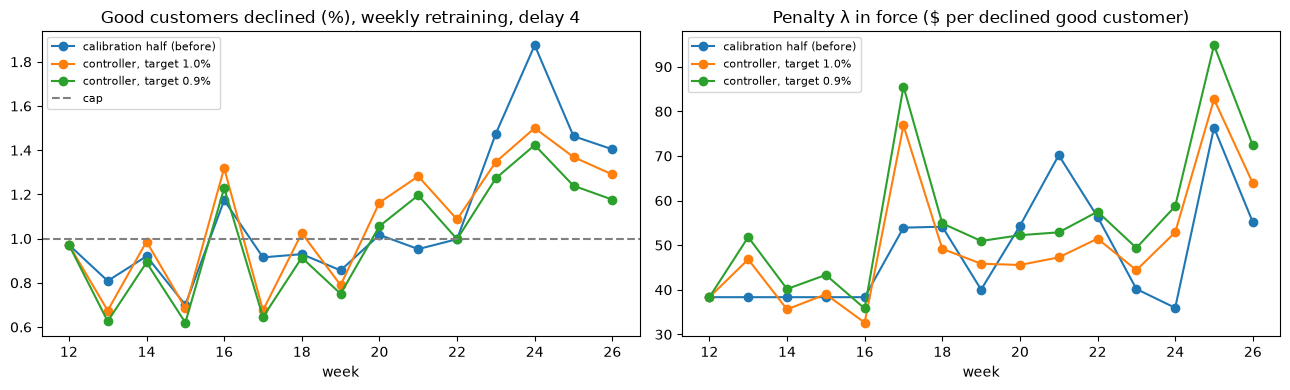

In [4]:
delay, policy = 4, "weekly"
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for method in METHODS:
    w = weekly[delay, policy, method]
    axes[0].plot(w.index, w["good_customers_declined"] * 100, marker="o", label=method)
    axes[1].plot(w.index, w["penalty"], marker="o", label=method)
axes[0].axhline(CAP * 100, color="gray", ls="--", label="cap")
axes[0].set(title=f"Good customers declined (%), {policy} retraining, delay {delay}", xlabel="week")
axes[1].set(title="Penalty λ in force ($ per declined good customer)", xlabel="week")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "cap_control.png", dpi=120, bbox_inches="tight")

In [5]:
# Does the label-free estimate track the realised rate? (calibration check, per week, controller 1.0%)
w = weekly[4, "weekly", "controller, target 1.0%"]
print(f"realised good-customer decline rate under the 1.0% controller: mean {w['good_customers_declined'].mean():.3%}, "
      f"sd {w['good_customers_declined'].std():.3%}, range {w['good_customers_declined'].min():.3%}-{w['good_customers_declined'].max():.3%}")

realised good-customer decline rate under the 1.0% controller: mean 1.078%, sd 0.277%, range 0.674%-1.500%
